# Imports

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import random

# Constants

In [2]:
seed = random.randint(0, 10000)
tf.random.set_seed(seed)
test_size = 0.15
val_size = 0.15
epochs = 50
batch_size = 1024

# Dataset

In [3]:
data = pd.read_csv("data/creditcard_2023.csv").drop(columns=["id"])
print(data.describe())

                 V1            V2            V3             V4            V5  \
count  5.686300e+05  5.686300e+05  5.686300e+05  568630.000000  5.686300e+05   
mean  -5.118237e-17 -5.118237e-17  1.023647e-16       0.000000  2.559118e-17   
std    1.000001e+00  1.000001e+00  1.000001e+00       1.000001  1.000001e+00   
min   -3.495584e+00 -4.996657e+01 -3.183760e+00      -4.951222 -9.952786e+00   
25%   -5.652859e-01 -4.866777e-01 -6.492987e-01      -0.656020 -2.934955e-01   
50%   -9.363846e-02 -1.358939e-01  3.528579e-04      -0.073762  8.108788e-02   
75%    8.326582e-01  3.435552e-01  6.285380e-01       0.707005  4.397368e-01   
max    2.229046e+00  4.361865e+00  1.412583e+01       3.201536  4.271689e+01   

                 V6             V7            V8             V9           V10  \
count  5.686300e+05  568630.000000  5.686300e+05  568630.000000  5.686300e+05   
mean   2.559118e-17       0.000000  1.279559e-17       0.000000  1.023647e-16   
std    1.000001e+00       1.000001  

# Split into Training, Validation, and Test sets

In [4]:
x = data.drop(columns=["Class"])
y = data["Class"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=test_size, random_state=seed, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=val_size, random_state=seed, stratify=y_train
)

# Scale with RobustScaler

In [5]:
# Robust Scaler for feature scaling used due handle outliers
scaler = RobustScaler()

x_train = pd.DataFrame(
    scaler.fit_transform(x_train), columns=x_train.columns, index=x_train.index
)

x_val = pd.DataFrame(
    scaler.transform(x_val), columns=x_val.columns, index=x_val.index
)

x_test = pd.DataFrame(
    scaler.transform(x_test), columns=x_test.columns, index=x_test.index
)

print(f"There are a total of {data.isna().sum().sum()} missing values in the dataset.")
data.describe()

There are a total of 0 missing values in the dataset.


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,5.686300e+05,5.686300e+05,5.686300e+05,568630.000000,5.686300e+05,5.686300e+05,568630.000000,5.686300e+05,568630.000000,5.686300e+05,...,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,568630.000000,568630.0
mean,-5.118237e-17,-5.118237e-17,1.023647e-16,0.000000,2.559118e-17,2.559118e-17,0.000000,1.279559e-17,0.000000,1.023647e-16,...,1.279559e-17,1.599449e-18,5.598072e-18,-2.559118e-17,-4.478457e-17,-6.397796e-18,-2.559118e-17,3.198898e-17,12041.957635,0.5
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001,1.000001e+00,1.000001e+00,1.000001,1.000001e+00,1.000001,1.000001e+00,...,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,6919.644449,0.5
min,-3.495584e+00,-4.996657e+01,-3.183760e+00,-4.951222,-9.952786e+00,-2.111111e+01,-4.351839,-1.075634e+01,-3.751919,-3.163276e+00,...,-1.938252e+01,-7.734798e+00,-3.029545e+01,-4.067968e+00,-1.361263e+01,-8.226969e+00,-1.049863e+01,-3.903524e+01,50.010000,0.0
25%,-5.652859e-01,-4.866777e-01,-6.492987e-01,-0.656020,-2.934955e-01,-4.458712e-01,-0.283533,-1.922572e-01,-0.568745,-5.901008e-01,...,-1.664408e-01,-4.904892e-01,-2.376289e-01,-6.515801e-01,-5.541485e-01,-6.318948e-01,-3.049607e-01,-2.318783e-01,6054.892500,0.0
50%,-9.363846e-02,-1.358939e-01,3.528579e-04,-0.073762,8.108788e-02,7.871758e-02,0.233366,-1.145242e-01,0.092526,2.626145e-01,...,-3.743065e-02,-2.732881e-02,-5.968903e-02,1.590123e-02,-8.193162e-03,-1.189208e-02,-1.729111e-01,-1.392973e-02,12030.150000,0.5
75%,8.326582e-01,3.435552e-01,6.285380e-01,0.707005,4.397368e-01,4.977881e-01,0.525955,4.729905e-02,0.559262,5.924603e-01,...,1.479787e-01,4.638817e-01,1.557153e-01,7.007374e-01,5.500147e-01,6.728879e-01,3.340230e-01,4.095903e-01,18036.330000,1.0
max,2.229046e+00,4.361865e+00,1.412583e+01,3.201536,4.271689e+01,2.616840e+01,217.873038,5.958040e+00,20.270062,3.172271e+01,...,8.087080e+00,1.263251e+01,3.170763e+01,1.296564e+01,1.462151e+01,5.623285e+00,1.132311e+02,7.725594e+01,24039.930000,1.0


# Define Architectures

In [6]:
architectures = [
    [16],
    [32, 16],
    [64, 32, 16],
    [128, 64, 32, 16]
]

# Build the model for each architecture

In [7]:
def run_model(architecture, num_input_features):
    tf.keras.utils.set_random_seed(seed)

    model = Sequential()
    model.add(Input(shape=(num_input_features,)))
    # tanh used due to data being mostly centerd around zero
    for units in architecture:
        model.add(Dense(units, activation='tanh'))
    # sigmoid used to output probability for binary classification
    model.add(Dense(1, activation='sigmoid'))

    # binary_crossentropy used for binary classification, works
    # adam used since it is simple and works well
    # f1_score is tuned here using the threshold parameter to work with the binary classification better
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.F1Score(threshold=0.5, average='micro'), 
            'recall', 
            'precision'
        ]
    )

    history = model.fit(
        x_train,
        y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(x_val, y_val),
        verbose=0
    )

    metrics = model.evaluate(x_test, y_test, return_dict=True, verbose=0)

    y_prob = model.predict(x_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    matrix = ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Legitimate", "Fraud"]
    )

    matrix.ax_.set_title("Test metrics - Architecture: " + str(architecture))
    matrix.figure_.tight_layout()

    return {"architecture": architecture, "history": history.history, "model": model, "metrics": metrics, "classification_report": classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"], digits=4)}

# Run the neural network for each architecture

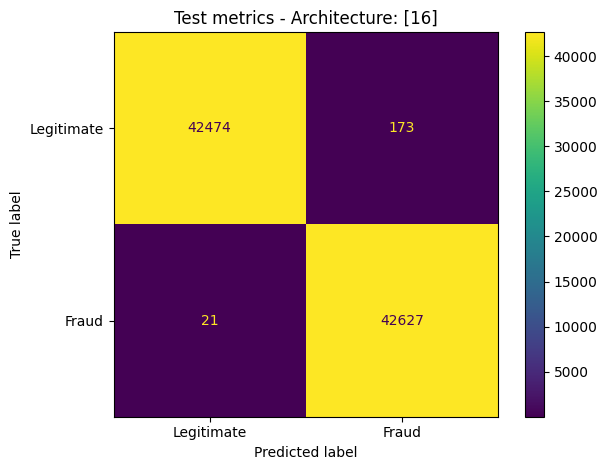

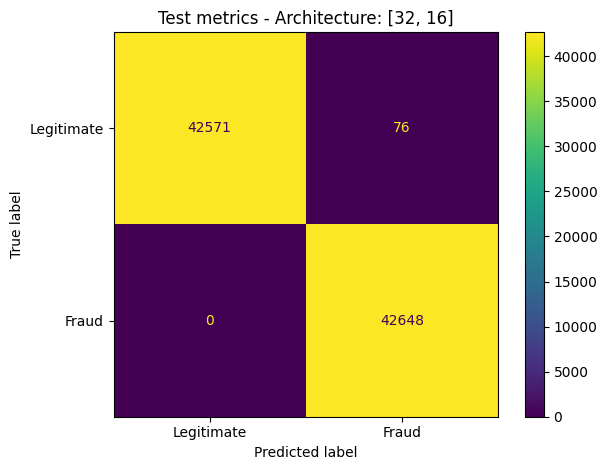

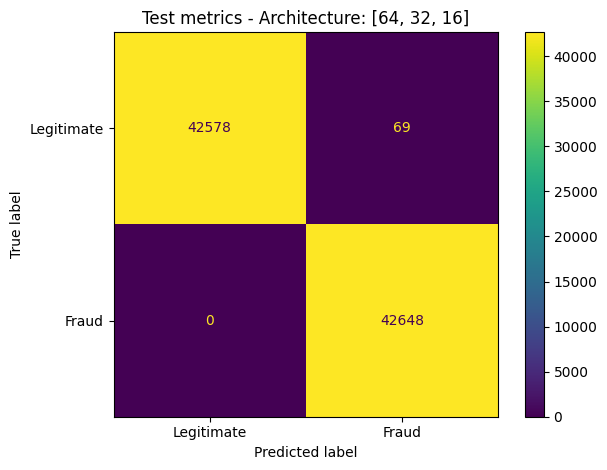

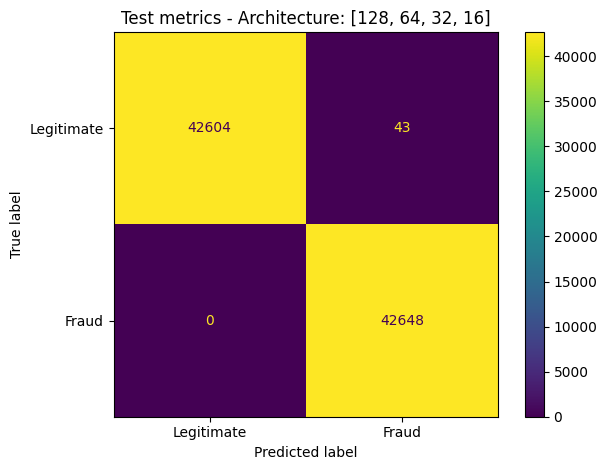

In [8]:
results = [run_model(architecture, num_input_features=29) for architecture in architectures]

# Report Results

Classification Report:
              precision    recall  f1-score   support

  Legitimate     0.9995    0.9959    0.9977     42647
       Fraud     0.9960    0.9995    0.9977     42648

    accuracy                         0.9977     85295
   macro avg     0.9977    0.9977    0.9977     85295
weighted avg     0.9977    0.9977    0.9977     85295

Metrics:
accuracy: 0.9977255463600159
f1_score: 0.9977295994758606
loss: 0.012117699719965458
precision: 0.9959579706192017
recall: 0.9995076060295105
Architecture: [16]


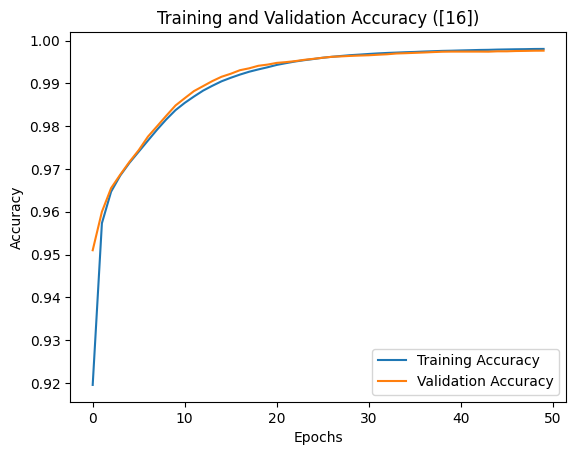

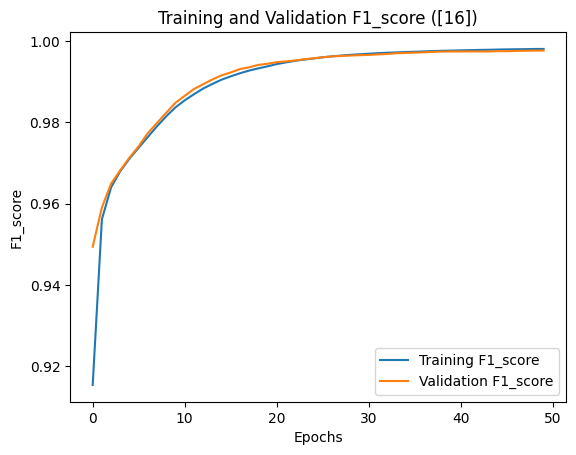

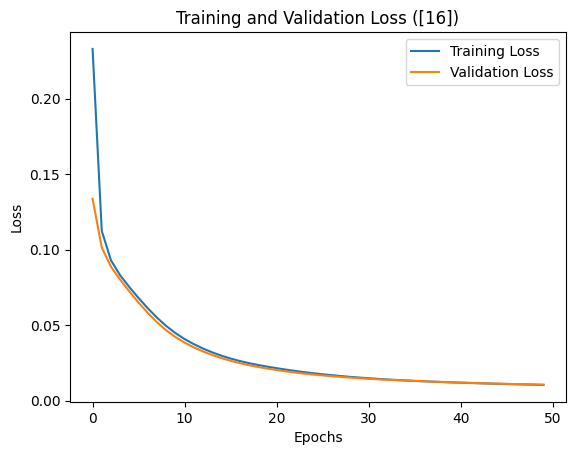

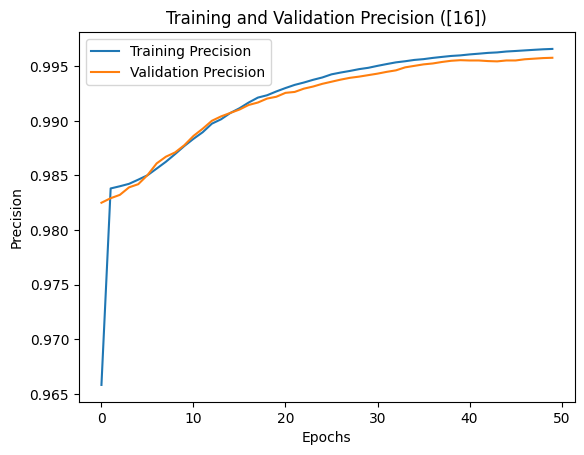

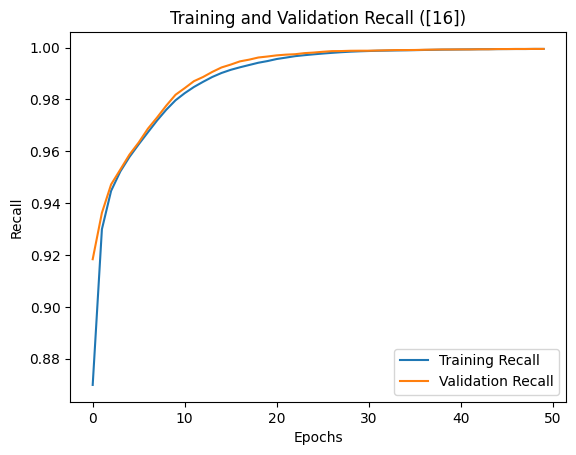

Classification Report:
              precision    recall  f1-score   support

  Legitimate     1.0000    0.9982    0.9991     42647
       Fraud     0.9982    1.0000    0.9991     42648

    accuracy                         0.9991     85295
   macro avg     0.9991    0.9991    0.9991     85295
weighted avg     0.9991    0.9991    0.9991     85295

Metrics:
accuracy: 0.9991089701652527
f1_score: 0.9991097450256348
loss: 0.004529640544205904
precision: 0.9982211589813232
recall: 1.0
Architecture: [32, 16]


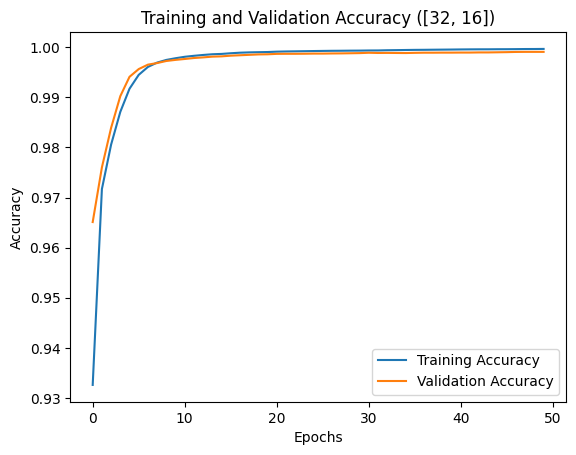

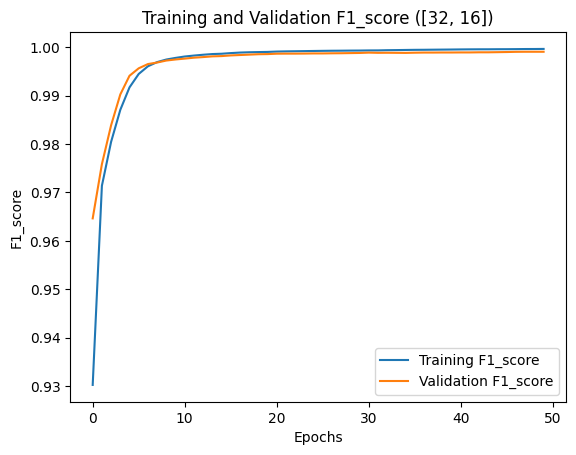

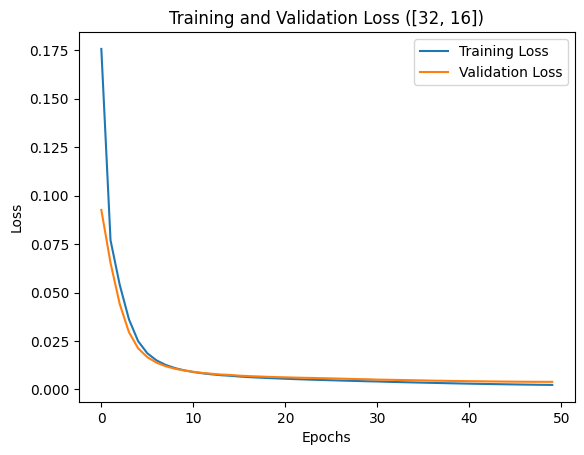

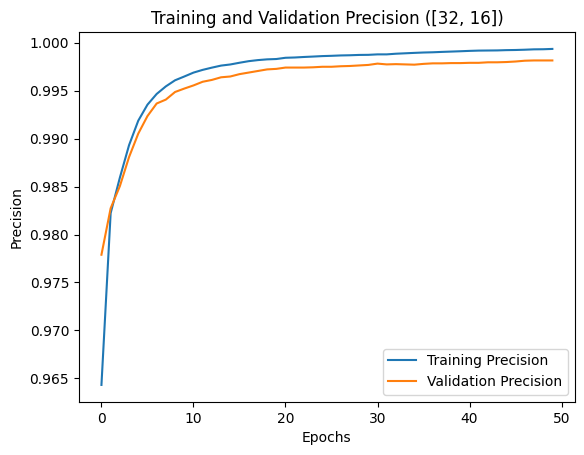

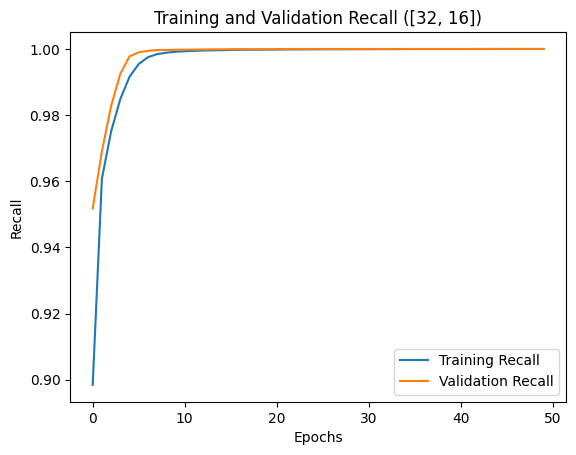

Classification Report:
              precision    recall  f1-score   support

  Legitimate     1.0000    0.9984    0.9992     42647
       Fraud     0.9984    1.0000    0.9992     42648

    accuracy                         0.9992     85295
   macro avg     0.9992    0.9992    0.9992     85295
weighted avg     0.9992    0.9992    0.9992     85295

Metrics:
accuracy: 0.9991910457611084
f1_score: 0.9991916418075562
loss: 0.004417124669998884
precision: 0.9983847141265869
recall: 1.0
Architecture: [64, 32, 16]


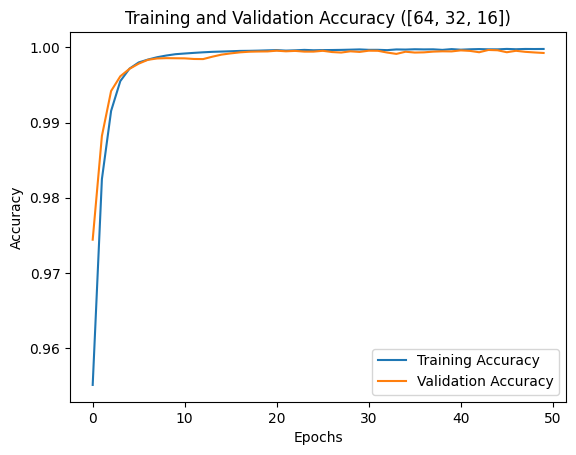

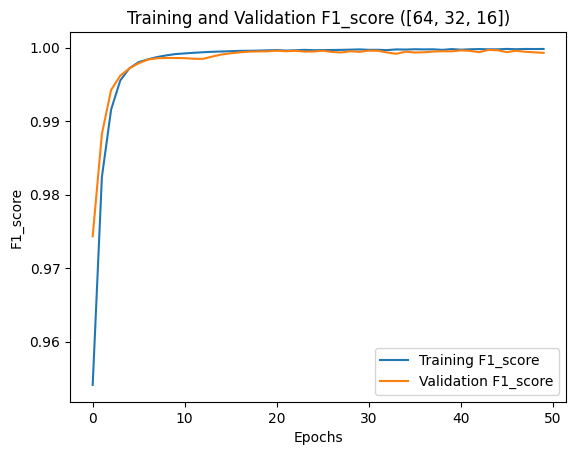

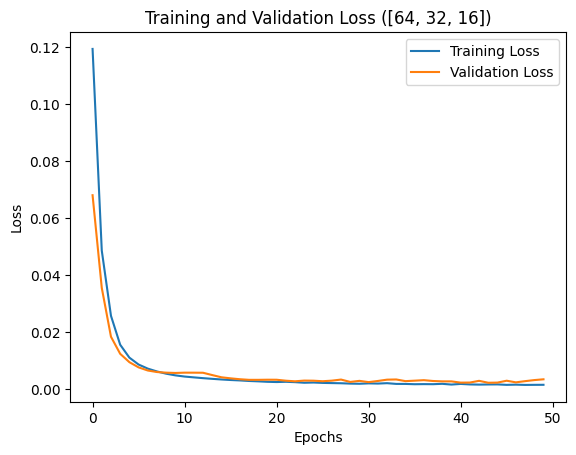

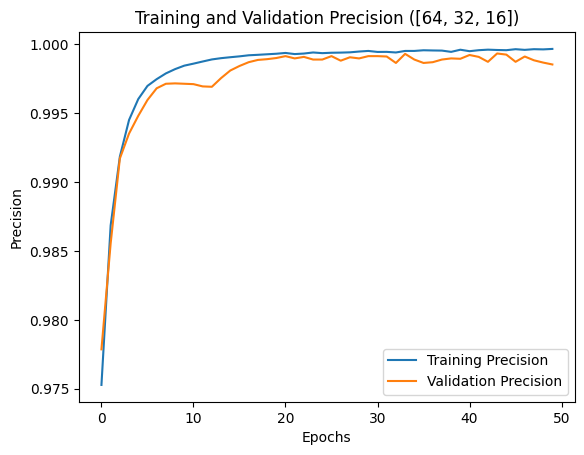

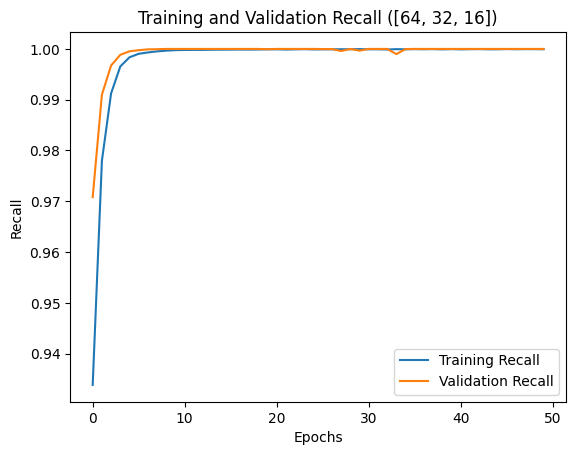

Classification Report:
              precision    recall  f1-score   support

  Legitimate     1.0000    0.9990    0.9995     42647
       Fraud     0.9990    1.0000    0.9995     42648

    accuracy                         0.9995     85295
   macro avg     0.9995    0.9995    0.9995     85295
weighted avg     0.9995    0.9995    0.9995     85295

Metrics:
accuracy: 0.9994958639144897
f1_score: 0.9994961023330688
loss: 0.0032763900235295296
precision: 0.9989927411079407
recall: 1.0
Architecture: [128, 64, 32, 16]


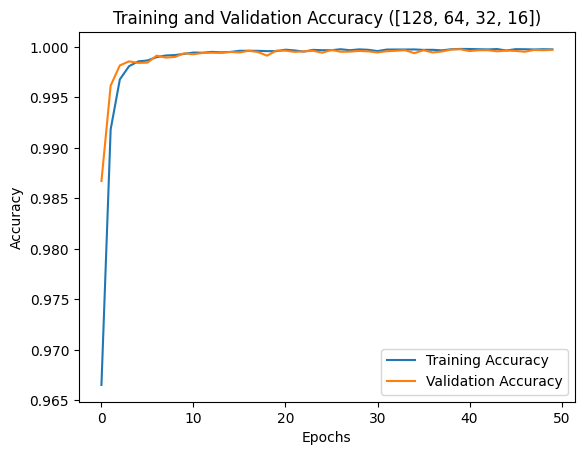

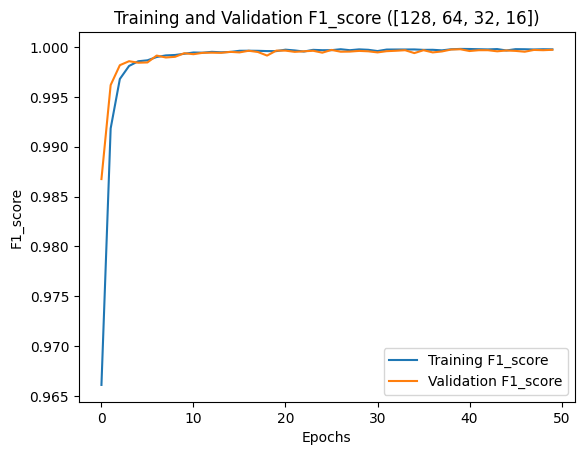

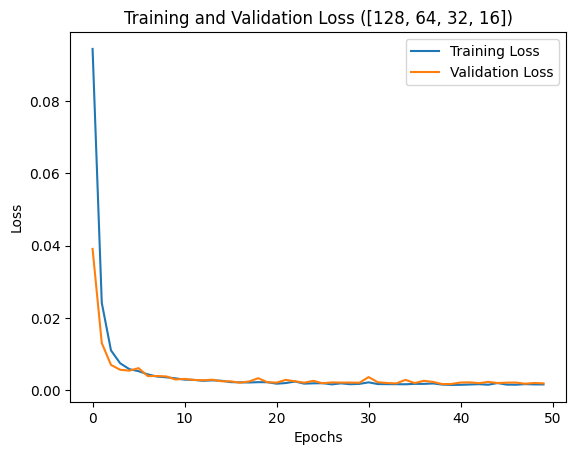

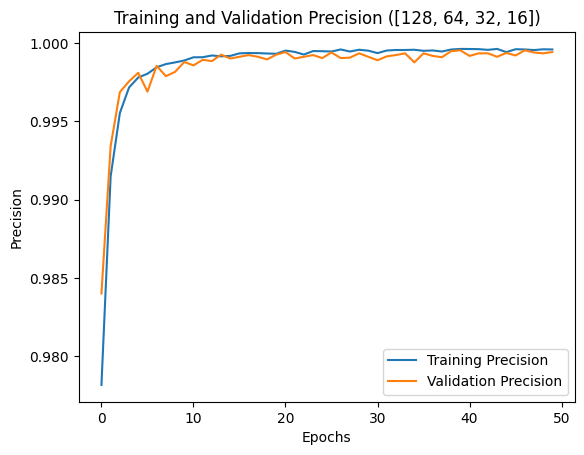

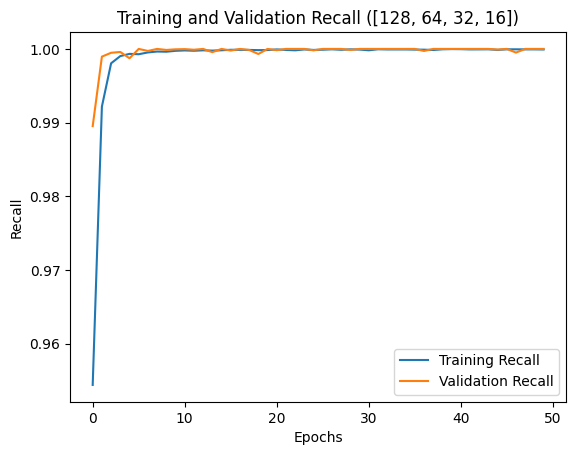

In [9]:
training_validation_metrics = ['accuracy', 'f1_score', 'loss', 'precision', 'recall']
for result in results:
    print("Classification Report:")
    print(result["classification_report"])
    print("Metrics:")
    for metric, value in result["metrics"].items():
        print(f"{metric}: {value}")
    architecture = str(result["architecture"])
    print("Architecture:", architecture)
    for metric in training_validation_metrics:
        plt.plot(result["history"][metric], label=f"Training {metric.capitalize()}")
        plt.plot(result["history"][f"val_{metric}"], label=f"Validation {metric.capitalize()}")
        plt.title(f"Training and Validation {metric.capitalize()} ({architecture})")
        plt.xlabel("Epochs")
        plt.ylabel(metric.capitalize())
        plt.legend()
        plt.show()